<a href="https://colab.research.google.com/github/amahendra/Sequential_Decision_Analytics_Modeling_Course/blob/main/Praktikum_LSTM_Suhu_Jakarta_Sederhana.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum LSTM: Prediksi Suhu Jakarta 1 Jam ke Depan

**Mata kuliah:** Sequential Data Analytics and Modeling (AID01) — S1 Artificial Intelligence, Universitas Bunda Mulia

**Tujuan:** Mempelajari alur LSTM secara sederhana, dari membaca CSV sampai membandingkan prediksi dengan suhu sebenarnya.

**Dataset:** `Dataset_Cuaca_Jakarta_Sintetis_2024_10Menit.csv` (52.704 baris; data **sintetis**, bukan pengukuran BMKG).

**Ide:** Gunakan suhu selama **6 jam terakhir** (36 pembacaan × 10 menit) untuk memperkirakan suhu **1 jam setelah pembacaan terakhir** (6 interval × 10 menit). Kita hanya menggunakan satu kolom suhu supaya mudah dipahami. Sebelum training, suhu diubah ke skala sederhana `(suhu - 20) / 20` dan dikembalikan ke °C saat evaluasi.

Jalankan sel dari atas ke bawah di Google Colab. Runtime CPU sudah cukup; GPU opsional.

## 1. Baca file CSV

Upload file CSV melalui panel **Files** di sebelah kiri Colab. File harus berada di `/content/` (jika memakai `/content/sample_data/`, sesuaikan path).

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Sesuaikan lokasi file jika berbeda
nama_file = '/content/Dataset_Cuaca_Jakarta_Sintetis_2024_10Menit.csv'
data = pd.read_csv(nama_file)

print('Jumlah data:', len(data))
print(data[['Date Time', 'T (degC)']].head())

Jumlah data: 52704
             Date Time  T (degC)
0  2024-01-01 00:00:00     26.39
1  2024-01-01 00:10:00     26.25
2  2024-01-01 00:20:00     26.22
3  2024-01-01 00:30:00     26.27
4  2024-01-01 00:40:00     26.22


## 2. Ambil kolom suhu

`T (degC)` adalah suhu dalam derajat Celsius. Data asli berjarak 10 menit. Untuk praktikum ini, kita tidak memakai kolom cuaca lain. Nilai suhu diskalakan menggunakan `(suhu - 20) / 20` agar LSTM mudah dilatih.

In [5]:
# Ubah tanggal menjadi format datetime lalu urutkan dari awal ke akhir
data["Date Time"] = pd.to_datetime(data["Date Time"])
data = data.sort_values("Date Time").reset_index(drop=True)

suhu = data["T (degC)"].to_numpy(dtype="float32")

# Skala tetap agar LSTM lebih mudah belajar
suhu_normal = (suhu - 20) / 20
print("Suhu pertama:", suhu[0], "°C")
print("Suhu terakhir:", suhu[-1], "°C")

Suhu pertama: 26.39 °C
Suhu terakhir: 27.57 °C


## 3. Lihat perubahan suhu

Grafik ini hanya menampilkan dua hari pertama agar mudah dibaca: `2 × 24 × 6 = 288` pembacaan.
- data cuaca ini dicatat setiap 10 menit sekali ($6\text{ kali per jam} \times 24\text{ jam} \times 2\text{ hari} = 288\text{ baris data}$).

In [ ]:
plt.figure(figsize=(11, 3))
plt.plot(data["Date Time"].iloc[:288], suhu[:288])
plt.title("Suhu Jakarta: Dua Hari Pertama (Sintetis)")
plt.xlabel("Waktu")
plt.ylabel("Suhu (°C)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Buat pasangan input dan target (sliding window)

LSTM memerlukan urutan angka, bukan satu angka.

- **Input X:** 36 suhu terakhir = 6 jam terakhir.
- **Target y:** suhu 1 jam **setelah waktu suhu terakhir di input**.
- Karena tiap data berjarak 10 menit, 1 jam = 6 langkah.

Contoh: jika input terakhir pukul **06.00**, target adalah suhu pukul **07.00**. Karena itu indeks target adalah `i + 36 + 5`, bukan `i + 36`.

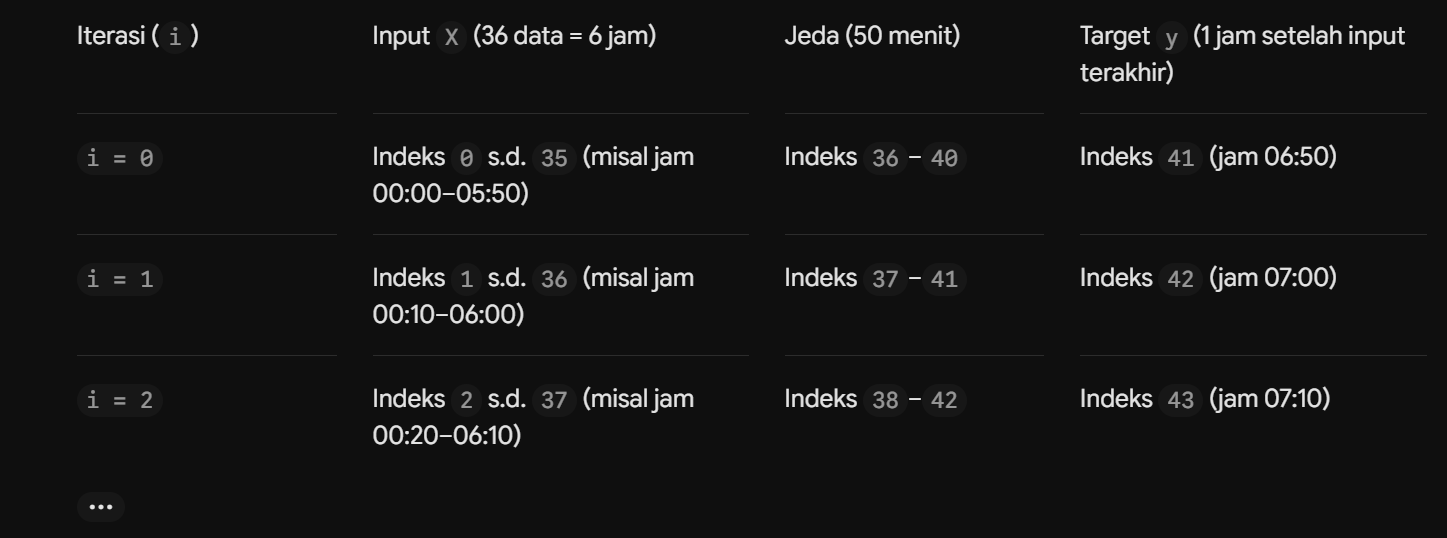


In [6]:
window = 36  # 36 x 10 menit = 6 jam
jarak = 6   # 6 x 10 menit = 1 jam

X = []
y = []

for i in range(len(suhu) - window - jarak + 1):
    X.append(suhu_normal[i : i + window])
    y.append(suhu_normal[i + window + jarak - 1])

X = np.array(X)
y = np.array(y)

# Bentuk yang diminta LSTM: (jumlah_contoh, jumlah_waktu, jumlah_fitur)
X = X.reshape((len(X), window, 1))

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Contoh: input terakhir (skala):", X[0, -1, 0])
print("Target 1 jam kemudian (skala):", y[0])

Bentuk X: (52663, 36, 1)
Bentuk y: (52663,)
Contoh: input terakhir (skala): 0.305
Target 1 jam kemudian (skala): 0.342


## 5. Bagi data secara berurutan

Jangan acak data deret waktu. Kita memakai 70% contoh pertama untuk training, 15% berikutnya untuk validation, dan 15% terakhir untuk testing. Validation untuk memantau training; test untuk mengukur hasil akhir.

In [7]:
n = len(X)
batas_train = int(n * 0.70)
batas_val = int(n * 0.85)

X_train, y_train = X[:batas_train], y[:batas_train]
X_val, y_val = X[batas_train:batas_val], y[batas_train:batas_val]
X_test, y_test = X[batas_val:], y[batas_val:]

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 36864
Validation: 7899
Testing: 7900


## 6. Buat model LSTM kecil

Gunakan satu layer LSTM dengan **16 neuron**, diikuti satu neuron output untuk menghasilkan **satu angka suhu**. Selama training, loss berada pada skala normalisasi. Hasil evaluasi akhir dinyatakan dalam °C.

In [8]:
# Ubah angka ini jika ingin bereksperimen
jumlah_neuron = 16
jumlah_epoch = 3

tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.Input(shape=(window, 1)),
    tf.keras.layers.LSTM(jumlah_neuron),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mae')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Latih model

Model melihat data training beberapa kali (`epoch`). Grafik loss akan membantu menilai apakah rata-rata kesalahan menurun (pada skala normalisasi). `shuffle=False` dipilih agar urutan contoh tidak diacak selama training.

Epoch 1/3
288/288 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0548 - val_loss: 0.0249
Epoch 2/3
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0236 - val_loss: 0.0222
Epoch 3/3
288/288 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0220 - val_loss: 0.0223


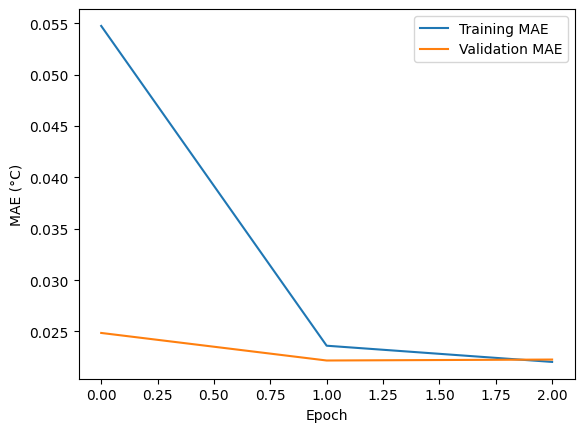

In [9]:
hasil = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=jumlah_epoch,
    batch_size=128,
    shuffle=False,
    verbose=1
)

plt.plot(hasil.history['loss'], label='Training MAE')
plt.plot(hasil.history['val_loss'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE (°C)')
plt.legend()
plt.show()

## 8. Prediksi dan hitung kesalahan

Prediksi dibuat pada data **testing** yang tidak dipakai untuk melatih model. Kita bandingkan dengan baseline sederhana: anggap suhu 1 jam mendatang sama dengan suhu terakhir yang sudah diketahui.

In [10]:
prediksi_normal = model.predict(X_test, verbose=0).flatten()

# Ubah hasil prediksi ke derajat Celsius
prediksi = prediksi_normal * 20 + 20
y_asli = y_test * 20 + 20

mae_lstm = np.mean(np.abs(y_asli - prediksi))

# Baseline: gunakan suhu terakhir pada setiap input
prediksi_baseline = X_test[:, -1, 0] * 20 + 20
mae_baseline = np.mean(np.abs(y_asli - prediksi_baseline))

print(f"MAE LSTM: {mae_lstm:.2f} °C")
print(f"MAE baseline: {mae_baseline:.2f} °C")
print("Semakin kecil MAE, semakin baik prediksi.")

MAE LSTM: 0.41 °C
MAE baseline: 0.63 °C
Semakin kecil MAE, semakin baik prediksi.


## 9. Bandingkan hasil prediksi dengan suhu aktual

Perhatikan apakah garis prediksi mengikuti perubahan suhu. Agar grafik tidak terlalu padat, tampilkan 100 contoh pertama pada data testing.

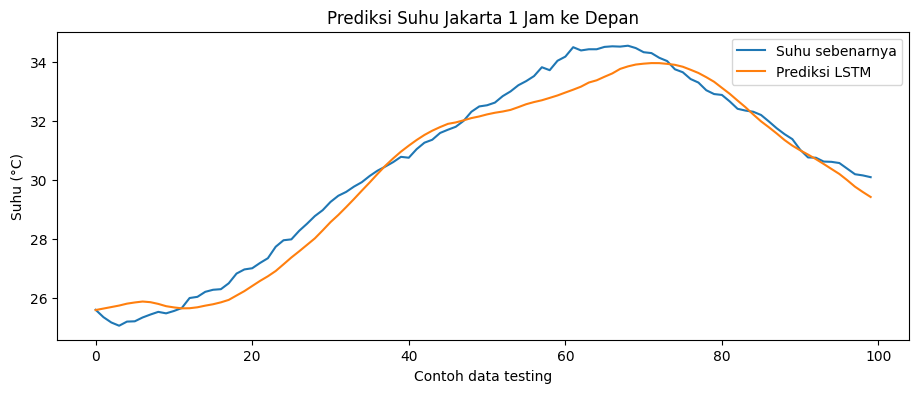

In [11]:
plt.figure(figsize=(11, 4))
plt.plot(y_asli[:100], label='Suhu sebenarnya')
plt.plot(prediksi[:100], label='Prediksi LSTM')
plt.xlabel('Contoh data testing')
plt.ylabel('Suhu (°C)')
plt.title('Prediksi Suhu Jakarta 1 Jam ke Depan')
plt.legend()
plt.show()

## Tugas mahasiswa (individual)

1. Jalankan seluruh notebook. Catat nilai **MAE LSTM** dan **MAE baseline**.
2. Ubah `jumlah_neuron` dari **16 ke 32**. Jalankan lagi mulai langkah 6. Apakah MAE membaik?
3. Kembalikan neuron ke **16**, ubah `jumlah_epoch` dari **3 ke 6**. Bagaimana pengaruhnya?
4. Kembalikan epoch ke **3**, ubah `window` dari **36 menjadi 12**. Jalankan ulang dari langkah 4 (bukan hanya langkah 6). Bagaimana hasilnya?
5. Jelaskan dengan kata-kata sendiri: mengapa data time series **tidak boleh dibagi secara acak** untuk evaluasi prediksi masa depan?

**Kumpulkan:** file `.ipynb` yang sudah dijalankan dan tabel ringkas berisi konfigurasi serta MAE dari setiap percobaan. **Tidak perlu membuat program baru.**

> Catatan: hasil pelatihan dapat sedikit berbeda antar-runtime. Untuk eksperimen yang adil, hanya ubah satu parameter setiap kali dan gunakan data testing yang sama pada percobaan dengan parameter lain yang sama. Dataset ini merupakan data sintetis untuk pembelajaran.